# Data Analysis

In [18]:
import importlib
from src.dataprocessor import * 
import src.func_utils
from src.modeltrainer import * 
from src.func_utils import *
import src.dataprocessor
import src.modeltrainer
importlib.reload(src.modeltrainer)
importlib.reload(src.dataprocessor)
importlib.reload(src.func_utils)
from src.dataprocessor import *
from src.modeltrainer import * 
from src.func_utils import *

Xtrain_molecular: str = r"./data/molecular_train.csv"
Xtrain_clinical: str = r"./data/clinical_train.csv"
target_train: str = r"./data/target_train.csv"

data_train_mol: pd.DataFrame = pd.read_csv(Xtrain_molecular)
data_train_cli: pd.DataFrame = pd.read_csv(Xtrain_clinical)
target_df: pd.DataFrame = pd.read_csv(target_train)

# Convert 'OS_YEARS' to numeric, forcing errors to NaN 

target_df['OS_YEARS'] = pd.to_numeric(target_df['OS_YEARS'], errors='coerce')

# Ensure 'OS_STATUS' is boolean
target_df['OS_STATUS'] = target_df['OS_STATUS'].astype(bool)

data = DataProcessor(data_train_mol, data_train_cli, target_df)

Let's quickly visualize our data to get familiar with it:

In [3]:
data.show()
data.get_data_shapes()

Molecular Data :
        ID CHR        START          END                REF ALT    GENE  \
0  P100000  11  119149248.0  119149248.0                  G   A     CBL   
1  P100000   5  131822301.0  131822301.0                  G   T    IRF1   
2  P100000   3   77694060.0   77694060.0                  G   C   ROBO2   
3  P100000   4  106164917.0  106164917.0                  G   T    TET2   
4  P100000   2   25468147.0   25468163.0  ACGAAGAGGGGGTGTTC   A  DNMT3A   

  PROTEIN_CHANGE                EFFECT     VAF   DEPTH  
0        p.C419Y  non_synonymous_codon  0.0830  1308.0  
1        p.Y164*           stop_gained  0.0220   532.0  
2            p.?   splice_site_variant  0.4100   876.0  
3       p.R1262L  non_synonymous_codon  0.4300   826.0  
4   p.E505fs*141    frameshift_variant  0.0898   942.0  

Clinical Data :
        ID CENTER  BM_BLAST    WBC  ANC  MONOCYTES    HB    PLT  \
0  P132697    MSK      14.0    2.8  0.2        0.7   7.6  119.0   
1  P132698    MSK       1.0    7.4  2.4

'the molecular data shape: (10935, 11), clinical data shape: (3323, 9), target data shape: (3323, 3)'

Let's start by briefly describing the database we have:

## Clinical Data (One Row per Patient)

Each patient is associated with a unique identifier and detailed clinical information:

* **ID:** Unique identifier for each patient.
* **CENTER:** The clinical center where the patient is treated.
* **BM_BLAST:** Percentage of blasts in the bone marrow, indicating the proportion of abnormal blood cells found in the patients' bone marrow.
* **WBC:** White Blood Cell count, measured in Giga/L (blood count parameter).
* **ANC:** Absolute Neutrophil Count in the blood, in Giga/L (blood count parameter).
* **MONOCYTES:** Number of monocytes in the blood, in Giga/L (blood count parameter).
* **HB:** Hemoglobin level, measured in g/dL (blood count parameter).
* **PLT:** Platelet count, in Giga/L (blood count parameter).
* **CYTOGENETICS:** Detailed description of the patient's karyotype, representing chromosomal abnormalities detected in blood cancer cells. Notations follow the ISCN standard, with typical markers like "46,XX" for a normal female karyotype or "46,XY" for a normal male karyotype. Abnormalities like monosomy 7 (loss of chromosome 7) indicate higher-risk disease.


## Molecular Gene Data (One Row per Somatic Mutation per Patient)

Somatic (acquired) mutations are mutations specific to cancer cells, not found in the patient's normal cells. This data captures genetic mutations at the cellular level:

* **ID:** Unique identifier for each patient.
* **CHR, START, END:** Chromosomal position of the mutation on the human genome.
* **REF, ALT:** The reference nucleotide and the alternative (mutant) nucleotide.
* **GENE:** The gene affected by the mutation.
* **PROTEIN_CHANGE:** The impact of the mutation on the protein produced by the gene.
* **EFFECT:** General classification of the mutation's impact on gene function.
* **VAF:** Variant Allele Fraction, representing the proportion of cells carrying the mutation.

## Target Data:
* **OS_STATUS**: Patient status (dead/alive) at last consultation
* **OS_YEARS**: How many years the patient has lived until now

We are interested in the frequency of our variables, as well as their missing values

In [4]:
freq_mol = variable_frequency_table(data.molecular_data)
freq_mol

,Variable,Unique_Values,Non_Missing_Count,Missing_Count,Non_Missing_%
0,ID,3026,10935,0,100.00%
1,CHR,23,10821,114,98.96%
2,START,4645,10821,114,98.96%
3,END,4664,10821,114,98.96%
4,REF,406,10821,114,98.96%
5,ALT,332,10821,114,98.96%
6,GENE,124,10935,0,100.00%
7,PROTEIN_CHANGE,4686,10923,12,99.89%
8,EFFECT,16,10935,0,100.00%
9,VAF,2952,10846,89,99.19%


We see that the variables START / END / REF / ALT / PROTEIN_CHANGE have very high variability relative to the number of observations we have, so we will not keep them.

In [5]:
mol_col_to_remove = ["START","END","REF","ALT","PROTEIN_CHANGE"]
data.remove_columns(mol_col_to_remove, data_type="molecular")

We will do the same for clinical data

In [6]:
freq_clin = variable_frequency_table(data.clinical_data)
freq_clin

,Variable,Unique_Values,Non_Missing_Count,Missing_Count,Non_Missing_%
0,ID,3323,3323,0,100.00%
1,CENTER,23,3323,0,100.00%
2,BM_BLAST,139,3214,109,96.72%
3,WBC,699,3051,272,91.81%
4,ANC,1026,3130,193,94.19%
5,MONOCYTES,609,2722,601,81.91%
6,HB,239,3213,110,96.69%
7,PLT,586,3199,124,96.27%
8,CYTOGENETICS,1194,2936,387,88.35%


In the clinical variable table, the only one that could be problematic is CYTOGENETICS, however this variable contains too much information to simply discard it, so we will try to transform it.

The transformation details are in func_utils and the source is in the report

In [7]:
data.apply_cytogenetics_classification()
data.create_cytogenetics_dummies()

,ID,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,CYTO_defavorable,CYTO_intermediaire,CYTO_normal
0,P132697,MSK,14.0,2.80,0.20,0.70,7.6,119.0,False,True,False
1,P132698,MSK,1.0,7.40,2.40,0.10,11.6,42.0,False,False,True
2,P116889,MSK,15.0,3.70,2.10,0.10,14.2,81.0,True,False,False
3,P132699,MSK,1.0,3.90,1.90,0.10,8.9,77.0,False,True,False
4,P132700,MSK,6.0,128.00,9.70,0.90,11.1,195.0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
3318,P121828,VU,1.0,3.70,2.53,0.53,8.9,499.0,False,False,True
3319,P121829,VU,0.0,4.20,2.40,0.22,10.6,49.0,False,True,False
3320,P121830,VU,0.0,1.80,0.55,0.29,9.4,86.0,True,False,False
3321,P121853,VU,5.0,1.37,0.37,0.11,11.4,102.0,False,True,False


## Molecular Data

We will create a danger variable which is the product of the VAF and DEPTH variables to designate the danger of the mutation (we assume that a mutation is more dangerous if it is deeper and the variation frequency is higher).
Once we have done that, we will aggregate using binary encoding for genes and effects

In [8]:
data.add_danger()
data.aggregate_genes()
data.temporary.head()

,ID,DANGER,GENE_ABL1,GENE_ARID1A,GENE_ARID2,GENE_ASXL1,GENE_ASXL2,GENE_ATRX,GENE_BAP1,GENE_BCL10,...,WBC,ANC,MONOCYTES,HB,PLT,CYTO_defavorable,CYTO_intermediaire,CYTO_normal,OS_YEARS,OS_STATUS
0,P100000,1323.4786,False,False,False,False,False,False,False,False,...,7.50,4.65,NaN,8.8,406.0,True,False,False,5.819178,False
1,P100001,271.2100,False,False,False,False,False,False,False,False,...,7.21,2.88,NaN,9.8,364.0,True,False,False,2.857534,False
2,P100002,351.8090,False,False,False,False,False,False,False,False,...,2.60,0.49,NaN,8.9,35.0,True,False,False,0.306849,True
3,P100004,607.9536,False,False,False,False,False,False,False,False,...,2.55,1.56,NaN,7.0,708.0,False,False,True,5.186301,False
4,P100006,490.1980,False,False,False,False,False,False,False,False,...,1.23,0.48,NaN,7.6,105.0,False,True,False,4.917808,False


In [9]:
resultats = clean_features_by_type(data.temporary,target_col="OS_YEARS")

CLASSIFICATION DES VARIABLES
Variables quantitatives (7):
  DANGER, BM_BLAST, WBC, ANC, MONOCYTES, HB, PLT

Variables qualitatives (169):
  ID, GENE_ABL1, GENE_ARID1A, GENE_ARID2, GENE_ASXL1, GENE_ASXL2, GENE_ATRX, GENE_BAP1, GENE_BCL10, GENE_BCOR...

CALCUL DES ASSOCIATIONS AVEC LA CIBLE

NETTOYAGE DES VARIABLES QUANTITATIVES
Initial: 7 variables
Conservées: 4 variables
Supprimées: 3 variables

Variables quantitatives sélectionnées (par corrélation):
  - PLT: |r| = 0.177
  - HB: |r| = 0.174
  - BM_BLAST: |r| = 0.156
  - DANGER: |r| = 0.130

NETTOYAGE DES VARIABLES QUALITATIVES
Initial: 169 variables
Conservées: 39 variables
Supprimées: 130 variables

Variables qualitatives sélectionnées (par p-value Chi²):
  - OS_STATUS: p = 0.0000
  - GENE_TP53: p = 0.0000
  - CENTER: p = 0.0000
  - CHR_17: p = 0.0000
  - CYTO_defavorable: p = 0.0000
  - CHR_21: p = 0.0000
  - GENE_RUNX1: p = 0.0000
  - GENE_SF3B1: p = 0.0000
  - CYTO_normal: p = 0.0000
  - GENE_ASXL1: p = 0.0000
  - CHR_1: p = 0.000

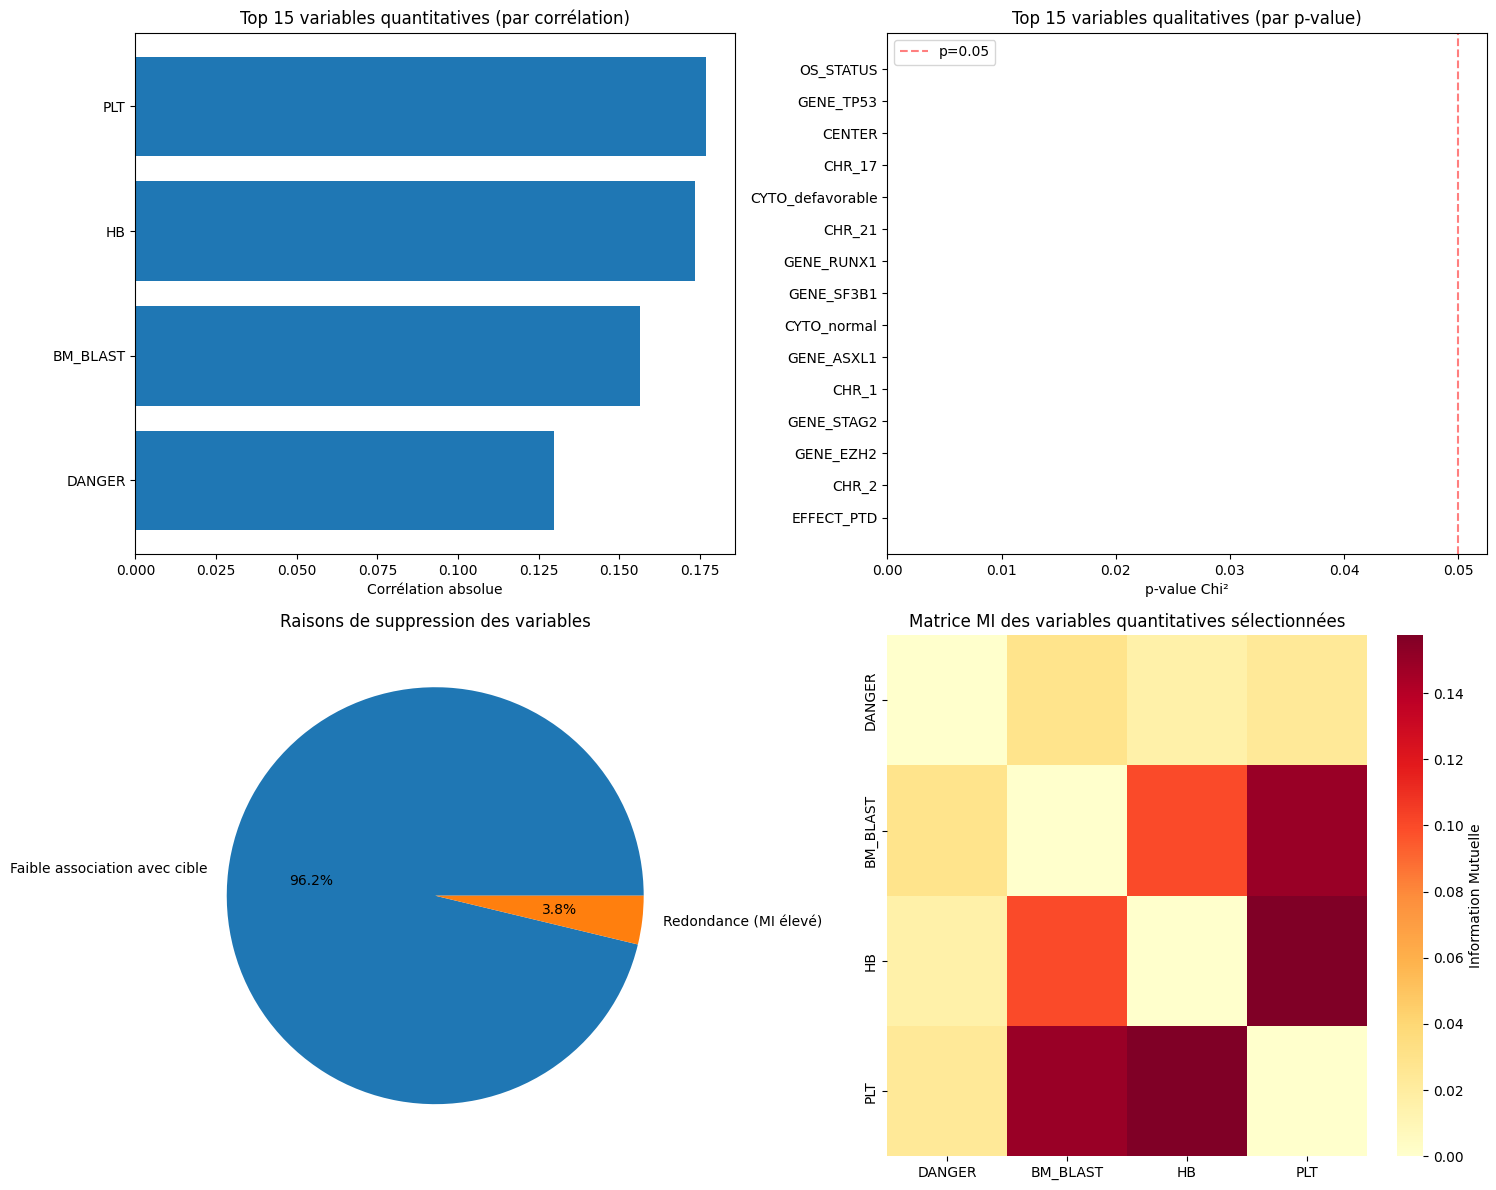

In [10]:
visualize_cleaning_results(resultats)

The p-values are not displayed because they are too small.

We obtain our final list and rearrange it to make it cleaner

In [ ]:
cols_for_training = resultats[1] + resultats[2]
if "OS_STATUS" in cols_for_training:
    cols_for_training.remove("OS_STATUS")
cols_for_training.remove("CENTER")
cols_for_training = ["ID"] + cols_for_training + ["OS_STATUS", "OS_YEARS"]

In [12]:
data.temporary[cols_for_training].isna().sum()

ID                                 0
DANGER                             0
BM_BLAST                         100
HB                               100
PLT                              114
CHR_17                             0
GENE_RUNX1                         0
GENE_STAG2                         0
GENE_ETV6                          0
EFFECT_frameshift_variant          0
GENE_U2AF1                         0
GENE_NPM1                          0
GENE_BCOR                          0
GENE_RAD21                         0
GENE_CEBPA                         0
GENE_FLT3                          0
CHR_1                              0
GENE_NRAS                          0
GENE_CBL                           0
GENE_ASXL1                         0
GENE_SRSF2                         0
CENTER                             0
GENE_GATA2                         0
GENE_CDKN2A                        0
EFFECT_PTD                         0
GENE_JAK2                          0
CHR_19                             0
C

We will handle the missing data later

In [13]:
data.save_data(cols = cols_for_training)

,ID,DANGER,BM_BLAST,HB,PLT,CHR_17,GENE_RUNX1,GENE_STAG2,GENE_ETV6,EFFECT_frameshift_variant,...,CHR_4,GENE_U2AF2,GENE_PTPN11,GENE_CUX1,GENE_SF3B1,CHR_11,GENE_MLL,EFFECT_initiator_codon_change,OS_STATUS,OS_YEARS
0,P100000,1323.4786,3.0,8.8,406.0,False,False,False,False,True,...,True,False,False,False,False,True,False,False,False,5.819178
1,P100001,271.2100,2.0,9.8,364.0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,2.857534
2,P100002,351.8090,15.0,8.9,35.0,True,False,False,False,False,...,False,False,False,False,False,False,False,False,True,0.306849
3,P100004,607.9536,3.0,7.0,708.0,False,False,True,False,True,...,False,False,False,False,False,False,False,False,False,5.186301
4,P100006,490.1980,1.0,7.6,105.0,True,False,False,False,True,...,True,False,False,False,False,False,False,False,False,4.917808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3021,P132725,4365.4240,12.0,11.5,61.0,False,False,True,False,True,...,False,False,False,False,False,False,False,False,False,4.290411
3022,P132726,347.0100,15.0,11.2,383.0,False,False,False,False,False,...,False,False,False,False,False,True,True,False,False,2.279452
3023,P132727,816.5240,5.0,11.3,44.0,False,False,False,False,True,...,False,False,False,False,False,True,False,False,False,0.578082
3024,P132728,2989.9348,2.0,8.2,14.0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,1.284932


In [14]:
X,Y = data.treated_data.drop(columns=["OS_STATUS","OS_YEARS"]), data.treated_data[["OS_STATUS","OS_YEARS"]]

In [15]:
# Étape 1: Split des patients AVANT de générer les paires
X_train, Y_train, X_val, Y_val, X_test, Y_test = split_patients_no_leakage(
    X, Y, 
    train_size=0.6, 
    val_size=0.2, 
    test_size=0.2,
    random_state=42,
    id_column='ID'
)

# Étape 2: Générer les paires pour chaque ensemble séparément
X_pairs_train, y_pairs_train, ids_train = generate_pairs_concat(
    X_train, Y_train, 
    max_pairs=150000,  # ou un nombre spécifique
    include_abs_diff=False,
    id_column='ID'
)

X_pairs_cal, y_pairs_cal, ids_cal = generate_pairs_concat(
    X_val, Y_val,max_pairs=50000,
    include_abs_diff=False,
    id_column='ID'
)

X_pairs_test, y_pairs_test, ids_test = generate_pairs_concat(
    X_test, Y_test,max_pairs=50000,
    include_abs_diff=False,
    id_column='ID'
)

print("\nRésumé final:")
print(f"Train: {len(y_pairs_train)} paires")
print(f"Calibration:   {len(y_pairs_cal)} paires")
print(f"Test:  {len(y_pairs_test)} paires")

Split réalisé sans leakage de patients:
  Train: 1815 patients (60.0%)
  Val:    605 patients (20.0%)
  Test:  606 patients (20.0%)
  ✓ Aucun chevauchement de patients détecté
CONCAT: 83555 paires générées, 84 features par paire
CONCAT: 28381 paires générées, 84 features par paire
CONCAT: 28465 paires générées, 84 features par paire

Résumé final:
Train: 83555 paires
Calibration:   28381 paires
Test:  28465 paires


In [19]:
save_pairs_to_excel(
    X_pairs_train, y_pairs_train, ids_train,
    X_pairs_cal, y_pairs_cal, ids_cal,
    X_pairs_test, y_pairs_test, ids_test)


✓ Données sauvegardées dans 'data/processed_data.xlsx'
  - Sheet 'train': 83555 paires
  - Sheet 'calibration': 28381 paires
  - Sheet 'test': 28465 paires


{'train':               patient_ids     feat_0 feat_1 feat_2 feat_3 feat_4 feat_5  \
 0      (P105712, P122349)  2532.0401    9.0   11.8  166.0   True  False   
 1      (P120377, P121051)   1062.232    NaN   11.3   17.0   True  False   
 2      (P116631, P122456)    1115.62    4.0   10.9  150.0   True  False   
 3      (P103003, P102571)    852.705    3.0    6.4   14.0   True  False   
 4      (P116623, P118399)  1983.6317   11.0   11.0   18.0   True   True   
 ...                   ...        ...    ...    ...    ...    ...    ...   
 83550  (P106045, P110675)    609.288    9.0   11.9  119.0  False  False   
 83551  (P105978, P116427)   119.2376    1.0   11.4   28.0  False  False   
 83552  (P120841, P102815)      347.4    1.0    9.0  310.0  False  False   
 83553  (P118461, P118188)    515.946    NaN    NaN    NaN  False   True   
 83554  (P110723, P100219)     282.74    2.0   11.6  440.0  False  False   
 
       feat_6 feat_7 feat_8  ... feat_75 feat_76 feat_77 feat_78 feat_79  \
 